<a href="https://colab.research.google.com/github/mayura-andrew/ml-experiments/blob/main/ECG_AFDB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
!pip install wfdb

In [19]:
import wfdb
wfdb.dl_database("afdb", dl_dir="./afdb")

Generating record list for: 00735
Generating record list for: 03665
Generating record list for: 04015
Generating record list for: 04043
Generating record list for: 04048
Generating record list for: 04126
Generating record list for: 04746
Generating record list for: 04908
Generating record list for: 04936
Generating record list for: 05091
Generating record list for: 05121
Generating record list for: 05261
Generating record list for: 06426
Generating record list for: 06453
Generating record list for: 06995
Generating record list for: 07162
Generating record list for: 07859
Generating record list for: 07879
Generating record list for: 07910
Generating record list for: 08215
Generating record list for: 08219
Generating record list for: 08378
Generating record list for: 08405
Generating record list for: 08434
Generating record list for: 08455
Generating list of all files for: 00735
Generating list of all files for: 03665
Generating list of all files for: 04015
Generating list of all files f

In [20]:
import os
import random
import wfdb
import numpy as np

# 1. Configuration (matches the MIT-BIH_AF/processed_data structure)
BASE_DIR = "./MIT-BIH_AF"
OUT_DIR = os.path.join(BASE_DIR, "processed_data")
os.makedirs(OUT_DIR, exist_ok=True)

FS = 250                          # 250 Hz sampling rate
WINDOW_SEC = 30                   # 30-second segments
WINDOW_SAMPLES = FS * WINDOW_SEC  # 7,500 samples
SAMPLES_PER_PATIENT = 200         # Matches tutorial's 200/patient (set None to keep all)
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# Download raw AFDB files into ./MIT-BIH_AF if not already present
if not os.path.exists(os.path.join(BASE_DIR, "04043.dat")):
    wfdb.dl_database("afdb", dl_dir=BASE_DIR)

# 23 valid records with .dat files (00735 and 03665 have no waveforms)
VALID_RECORDS = [
    "04015", "04043", "04048", "04126", "04746", "04908", "04936", "05091",
    "05121", "05261", "06426", "06453", "06995", "07162", "07859", "07879",
    "07910", "08215", "08219", "08378", "08405", "08434", "08455"
]

def build_binary_labels(num_samples, ann):
    """
    Expand .atr transition points into per-sample binary labels:
      1  = AFIB ('(AFIB')
      0  = Non-AF ('(N', '(AFL', '(J', etc.)
     -1  = Unlabeled (before first annotation)
    """
    labels = np.full(num_samples, -1, dtype=np.int8)
    transitions = []

    for sample_idx, note in zip(ann.sample, ann.aux_note):
        clean = note.strip().replace("\x00", "")
        if clean.startswith("("):
            lbl = 1 if clean == "(AFIB" else 0
            transitions.append((sample_idx, lbl))

    for i, (start_idx, lbl) in enumerate(transitions):
        end_idx = transitions[i + 1][0] if i + 1 < len(transitions) else num_samples
        labels[start_idx:end_idx] = lbl

    return labels

global_idx = 0

for rec_id in VALID_RECORDS:
    rec_path = os.path.join(BASE_DIR, rec_id)
    signal, _ = wfdb.rdsamp(rec_path)   # Shape: (N, 2)
    ann = wfdb.rdann(rec_path, "atr")

    num_samples = signal.shape[0]
    sample_labels = build_binary_labels(num_samples, ann)

    # Collect all clean, pure-rhythm 30s candidate windows for this patient
    candidates = []
    for start in range(0, num_samples - WINDOW_SAMPLES + 1, WINDOW_SAMPLES):
        end = start + WINDOW_SAMPLES
        win_sig = signal[start:end]
        win_lbl = sample_labels[start:end]

        # Skip unlabeled regions, mixed-rhythm boundaries, or flat zero-dropout blocks
        if np.any(win_lbl == -1):
            continue
        if len(np.unique(win_lbl)) > 1:
            continue
        if np.any(np.std(win_sig, axis=0) < 1e-4) or np.isnan(win_sig).any():
            continue

        candidates.append((start, end, int(win_lbl[0])))

    # Subsample up to 200 segments per patient (matching the tutorial's dataset size)
    if SAMPLES_PER_PATIENT is not None and len(candidates) > SAMPLES_PER_PATIENT:
        candidates = random.sample(candidates, SAMPLES_PER_PATIENT)

    # Save each segment as <patient_id>_<global_index>_<label>.npz
    for start, end, label in candidates:
        # Shape (2, 7500) -> channel-first for PyTorch / MONAI 1D ResNet18
        seg = signal[start:end].T.astype(np.float32)

        filename = f"{rec_id}_{global_idx}_{label}.npz"
        out_path = os.path.join(OUT_DIR, filename)

        np.savez_compressed(
            out_path,
            signal=seg,

            end=np.int64(end),
        )
        global_idx += 1

    print(f"Processed {rec_id}: saved {len(candidates)} segments")

print(f"\nDone! Total saved files in {OUT_DIR}: {global_idx}")

Processed 04015: saved 200 segments
Processed 04043: saved 200 segments
Processed 04048: saved 200 segments
Processed 04126: saved 200 segments
Processed 04746: saved 200 segments
Processed 04908: saved 200 segments
Processed 04936: saved 200 segments
Processed 05091: saved 200 segments
Processed 05121: saved 200 segments
Processed 05261: saved 200 segments
Processed 06426: saved 200 segments
Processed 06453: saved 200 segments
Processed 06995: saved 200 segments
Processed 07162: saved 200 segments
Processed 07859: saved 200 segments
Processed 07879: saved 200 segments
Processed 07910: saved 200 segments
Processed 08215: saved 200 segments
Processed 08219: saved 200 segments
Processed 08378: saved 200 segments
Processed 08405: saved 200 segments
Processed 08434: saved 200 segments
Processed 08455: saved 200 segments

Done! Total saved files in ./MIT-BIH_AF/processed_data: 4600


In [21]:
!pip install monai

In [22]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob

In [23]:
from numpy.random.mtrand import f
from pandas._libs.tslibs import timestamps
import wfdb


signal = wfdb.rdrecord("MIT-BIH_AF/04043").p_signal.T
annotation = wfdb.rdann("MIT-BIH_AF/04043", "atr")
timestamps = annotation.sample
labels = annotation.aux_note


print(f"Signal shape: {signal.shape}")
print()
print(f"Labels: {labels}, len={len(labels)}")
print()
print(f"Timestamps: {timestamps}, len={len(timestamps)}")



Signal shape: (2, 9205760)

Labels: ['(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N', '(AFIB', '(N

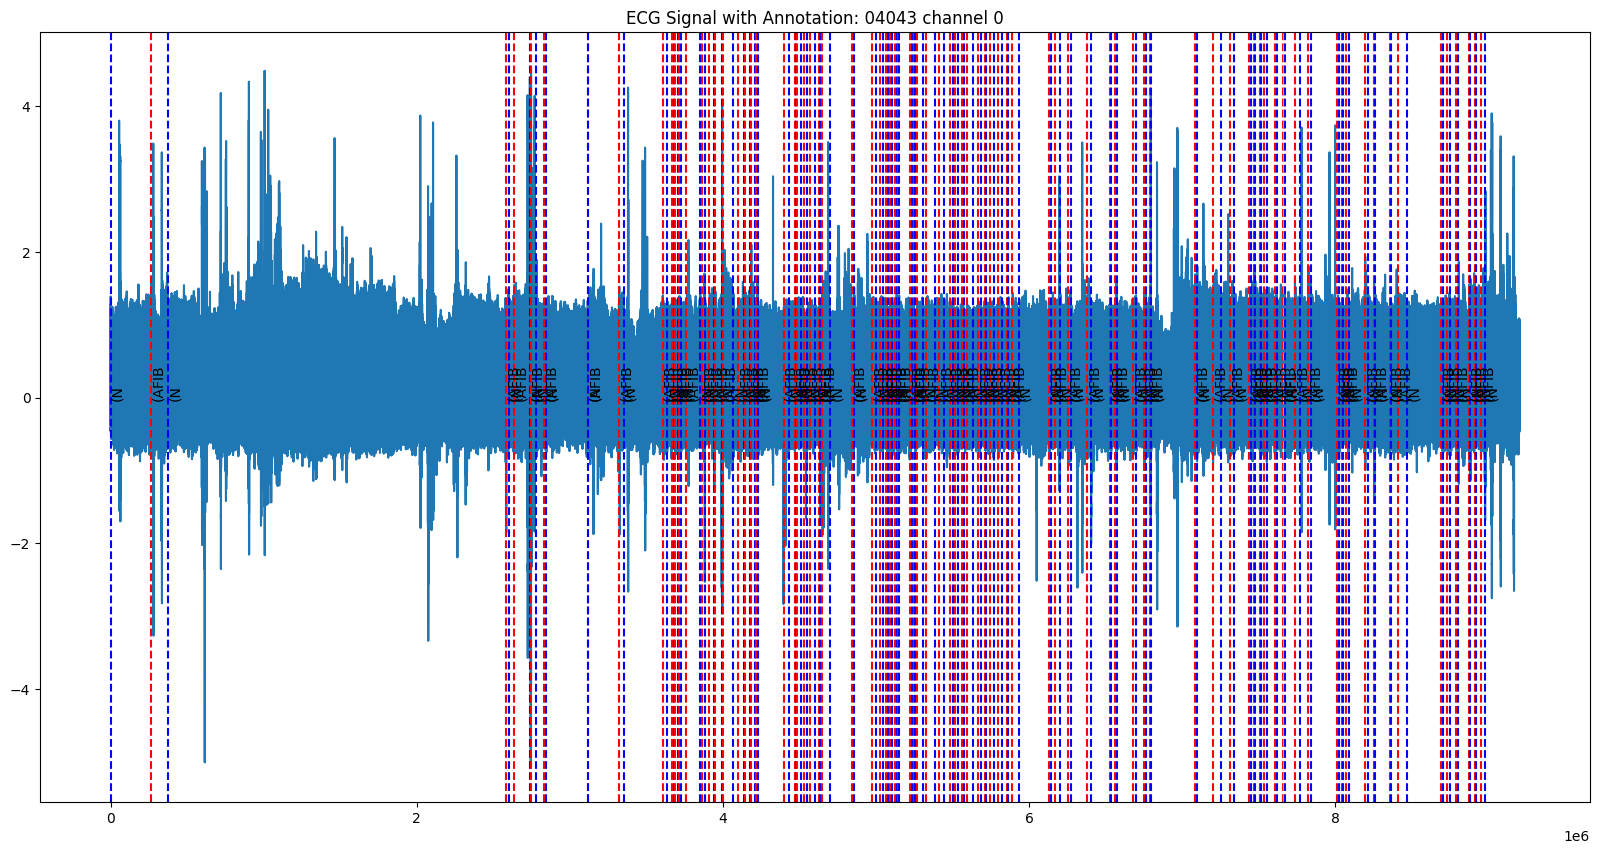

In [24]:
annotation_colors = {
    "(N": "blue",
    "(AFIB": "red",
    "(AFL": "orange",
    "(J": "green"
}

plt.figure(figsize=(20, 10))
plt.plot(signal[0])
# Use annotation.sample directly to bypass any shadowed variable names
for ts, label in zip(annotation.sample, labels):
  color = annotation_colors.get(label, "gray")
  plt.axvline(x=ts, color=color, linestyle="--")
  plt.text(ts, 0, label, rotation=90)
plt.title("ECG Signal with Annotation: 04043 channel 0")
plt.show()
plt.close()

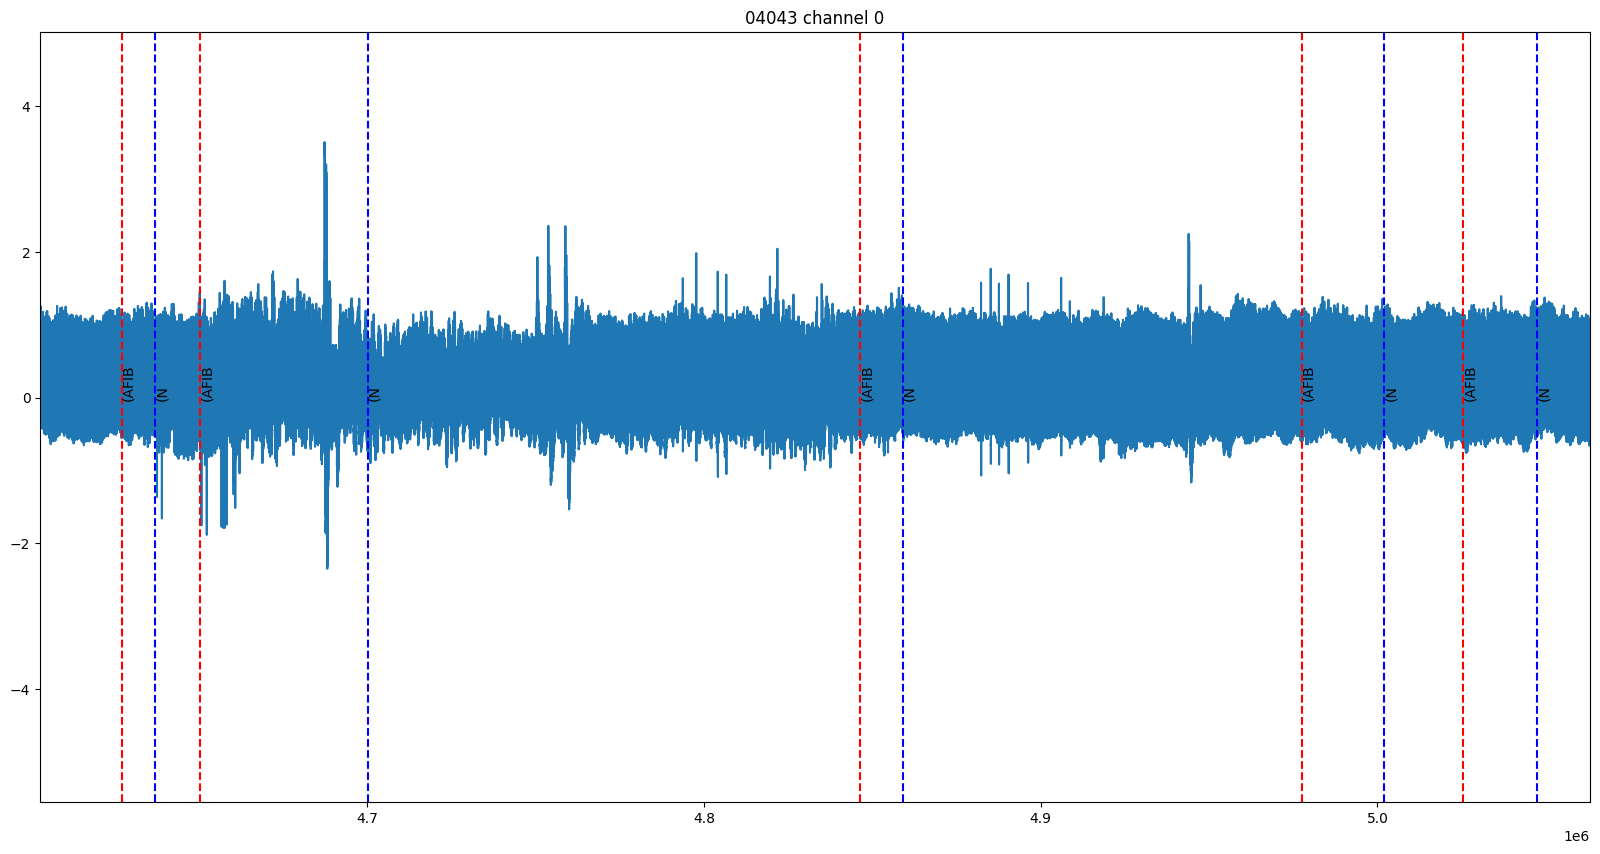

In [25]:
start = int(0.5 * len(signal[0]))
end = int(0.55 * len(signal[0]))
plt.figure(figsize=(20, 10))
# plt.plot(signal[0][start:end])
plt.plot(signal[0])
for timestamps, label in zip(timestamps, labels):
  if not start < timestamps < end:
    continue
  color = annotation_colors.get(label, "gray")
  plt.axvline(x=timestamps, color=annotation_colors[label], linestyle="--")
  plt.text(timestamps, 0, label, rotation=90)

plt.title("04043 channel 0")
plt.axis([start, end, None, None])
plt.show()
plt.close()

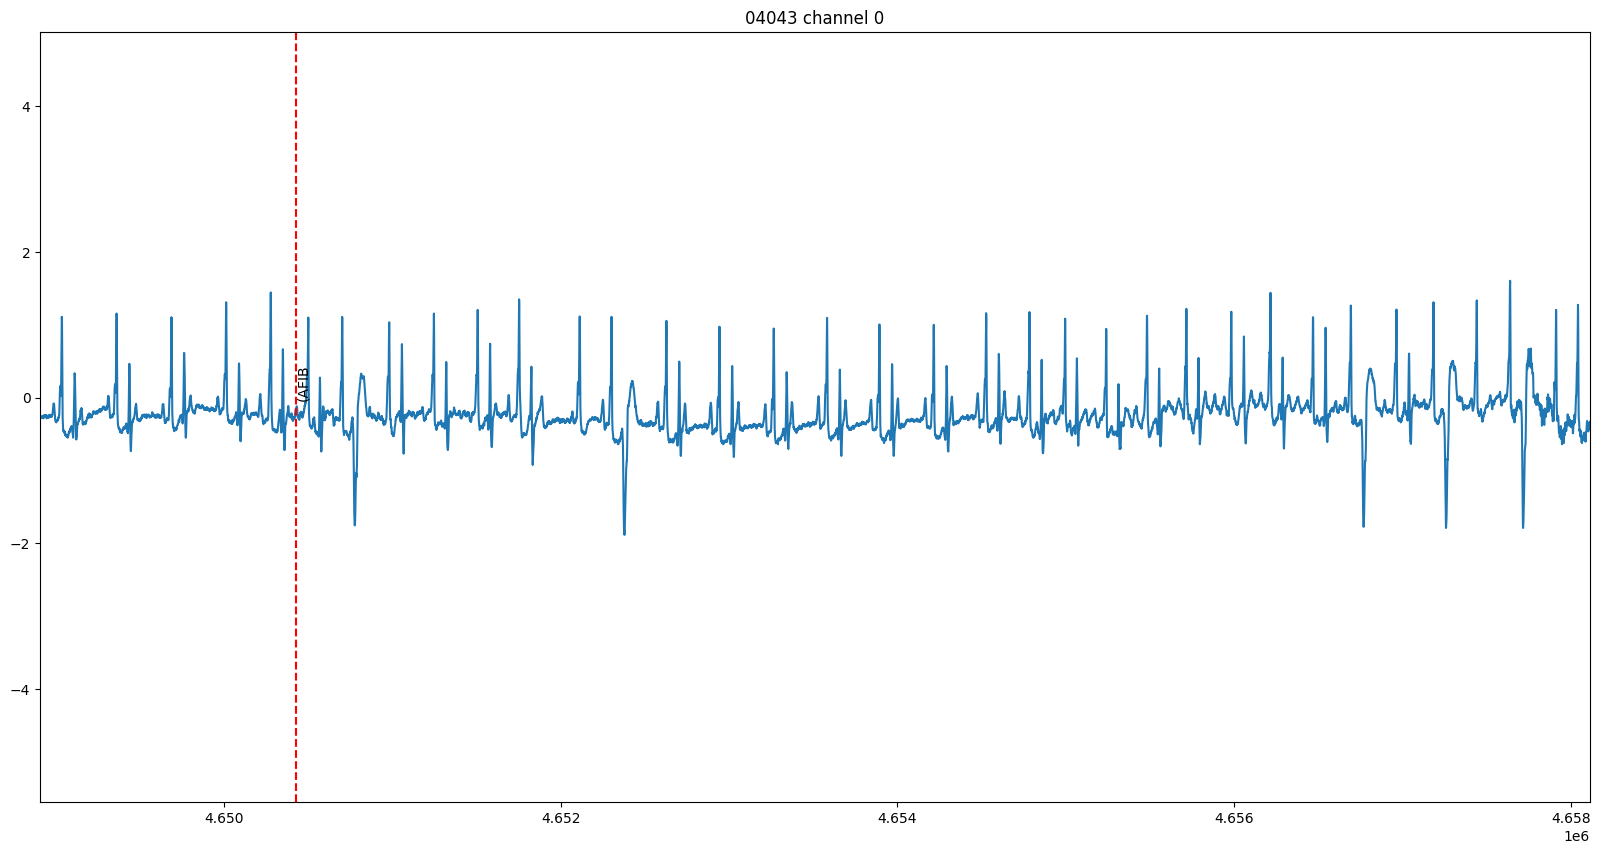

In [28]:
start = int(0.505 * len(signal[0]))
end = int(0.506 * len(signal[0]))
plt.figure(figsize=(20, 10))
# plt.plot(signal[0][start:end])
plt.plot(signal[0])
for ts, label in zip(annotation.sample, labels):
  if not start < ts < end:
    continue
  color = annotation_colors.get(label, "gray")
  plt.axvline(x=ts, color=color, linestyle="--")
  plt.text(ts, 0, label, rotation=90)

plt.title("04043 channel 0")
plt.axis([start, end, None, None])
plt.show()
plt.close()

In [30]:
data_path = "MIT-BIH_AF/processed_data"

# Get raw filenames directly from the directory using os.listdir
filenames = sorted([f for f in os.listdir(data_path) if f.endswith('.npz')])

print("Raw filenames:")
print(filenames[:10], f"... Total files: {len(filenames)}")

Raw filenames:
['04015_0_0.npz', '04015_100_0.npz', '04015_101_0.npz', '04015_102_0.npz', '04015_103_0.npz', '04015_104_0.npz', '04015_105_0.npz', '04015_106_0.npz', '04015_107_0.npz', '04015_108_0.npz'] ... Total files: 4600


In [31]:
from monai.utils import set_determinism
set_determinism(seed=42)

In [32]:
np.random.shuffle(filenames)


train_split = 0.8
validation_split = 0.1

train_filenames = filenames[:int(len(filenames) * train_split)]
validation_filenames = filenames[int(len(filenames) * train_split):int(len(filenames) * (train_split + validation_split))]
test_filenames = filenames[int(len(filenames) * (train_split + validation_split)):]

print(f"Train: {len(train_filenames)}")
print(f"Validation: {len(validation_filenames)}")
print(f"Test: {len(test_filenames)}")

Train: 3680
Validation: 460
Test: 460


In [33]:
import random

# Set seed for reproducibility
random.seed(42)

# 1. Start with the 23 original valid patient/record IDs
patients = [
    "04015", "04043", "04048", "04126", "04746", "04908", "04936", "05091",
    "05121", "05261", "06426", "06453", "06995", "07162", "07859", "07879",
    "07910", "08215", "08219", "08378", "08405", "08434", "08455"
]

# Shuffle patient list
shuffled_patients = patients.copy()
random.shuffle(shuffled_patients)

# 2. Split patients (18 Train, 2 Validation, 3 Test)
train_patients = shuffled_patients[:18]
val_patients = shuffled_patients[18:20]
test_patients = shuffled_patients[20:]

print(f"Train Patient IDs ({len(train_patients)}): {train_patients}")
print(f"Validation Patient IDs ({len(val_patients)}): {val_patients}")
print(f"Test Patient IDs ({len(test_patients)}): {test_patients}\n")

# 3. Map back to the generated segment filenames based on prefix
# Filenames format is: <patient_id>_<global_idx>_<label>.npz
train_filenames = [f for f in filenames if f.split('_')[0] in train_patients]
validation_filenames = [f for f in filenames if f.split('_')[0] in val_patients]
test_filenames = [f for f in filenames if f.split('_')[0] in test_patients]

print(f"Train Segments: {len(train_filenames)}")
print(f"Validation Segments: {len(validation_filenames)}")
print(f"Test Segments: {len(test_filenames)}")

Train Patient IDs (18): ['07910', '07879', '04048', '07859', '04908', '07162', '08215', '06995', '08455', '04936', '05261', '04043', '08378', '06453', '06426', '08434', '04746', '08219']
Validation Patient IDs (2): ['05091', '05121']
Test Patient IDs (3): ['04015', '04126', '08405']

Train Segments: 3600
Validation Segments: 400
Test Segments: 600


Files '07162' and '07859' cannot be used for validation or test since they are all comprised of AFIB

In [34]:
for filename in ["07162", "07859"]:
  if filename in validation_filenames:
    validation_filenames.remove(filename)
    validation_filenames.append(train_filenames[0])
    train_filenames.remove(filename)

  if filename in test_filenames:
    test_filenames.remove(filename)
    test_filenames.append(train_filenames[0])
    train_filenames.remove(train_filenames[0])
    train_filenames.append(filename)


In [36]:
# get filenames of samples
samples = glob(os.path.join(data_path, "*.npz"))
print(f"First 5 samples: {samples[:5]}")
print(f"Number of samples: {len(samples)}")

First 5 samples: ['MIT-BIH_AF/processed_data/04126_606_0.npz', 'MIT-BIH_AF/processed_data/07859_2897_1.npz', 'MIT-BIH_AF/processed_data/04043_315_1.npz', 'MIT-BIH_AF/processed_data/08215_3497_1.npz', 'MIT-BIH_AF/processed_data/08215_3453_1.npz']
Number of samples: 4600
